Large Scan stitch algorithm in NS Elements BR software is not great. Taking the individual images and stitching them in post (Nikon Eclipse Ti2 images)

In [1]:
import os
import imageio
import matplotlib.pyplot as plt
from tqdm import tqdm

import numpy as np
from scipy.ndimage import shift

data_dir = "data/"

In [2]:
sub_dir = "W0_unstitched_largeScan"
tif_files = sorted([file for file in os.listdir(data_dir+sub_dir) if file.endswith('.tif')])

In [3]:
tif_file=tif_files[0]

In [4]:
img = imageio.imread(data_dir+sub_dir+"/{}".format(tif_file))

/var/folders/2j/vdv93b7508qfh_tr2nx03dh80000gp/T/ipykernel_57166/1672924654.py:1: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(data_dir+sub_dir+"/{}".format(tif_file))


In [5]:
down_factor = 8

down_sampled_imgs = []
for i in tqdm(range(len(tif_files))):
    tif_file = tif_files[i]
    img = imageio.imread(data_dir+sub_dir+"/{}".format(tif_file))
    img = img[::down_factor, ::down_factor]

    # normalise the image 
    img = img - img.min()
    img = img / img.max()
    img = img * 255

    down_sampled_imgs.append(img)

  0%|          | 0/121 [00:00<?, ?it/s]/var/folders/2j/vdv93b7508qfh_tr2nx03dh80000gp/T/ipykernel_57166/1983935486.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(data_dir+sub_dir+"/{}".format(tif_file))
100%|██████████| 121/121 [00:25<00:00,  4.79it/s]


In [6]:
n_row, n_col = 11, 11
cols = []
for col_i in range(n_col):
    cols.append(np.concatenate(down_sampled_imgs[n_col*col_i:n_col*(col_i+1) - 1], axis=0))

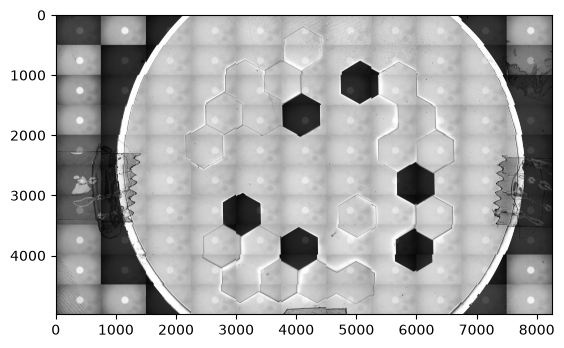

In [7]:
%matplotlib inline
plt.imshow(np.concatenate(cols,axis=1), cmap='gray')
plt.show()

In [8]:
%matplotlib qt
plt.imshow(down_sampled_imgs[0], cmap='gray')

Find centers using the internal source spot

In [20]:
from skimage import feature
from skimage.transform import hough_circle, hough_circle_peaks


In [22]:
edges, centers = [], []
radii = np.arange(55, 70, 2) # try a range of plausible radii
for img in down_sampled_imgs:
    edge = feature.canny(img, sigma=3)
    edges.append(edge)

    hough_res = hough_circle(edge, radii)

    accums, cx, cy, radii_found = hough_circle_peaks(
        hough_res, radii, total_num_peaks=1
    )

    centers.append([cx[0], cy[0]])


In [23]:
cols_edges = []
for col_i in range(n_col):
    cols_edges.append(np.concatenate(edges[n_col*col_i:n_col*(col_i+1) - 1], axis=0))

edges_net_img = np.concatenate(cols_edges, axis=1)

In [ ]:
shifted_cens = []
for cen in centers:
    shifted_cens.append([cen[0] - 512/down_factor, cen[1] - 512/down_factor])

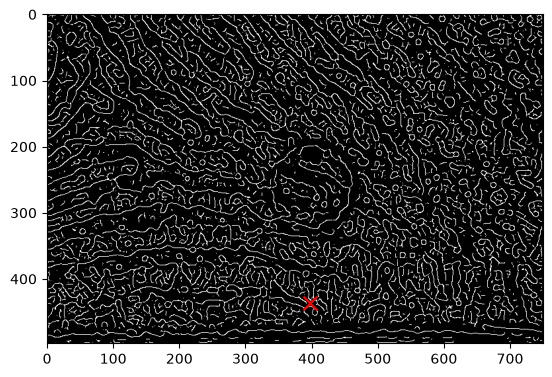

In [29]:
plt.imshow(edges[10], cmap='gray')
plt.scatter(centers[10][0], centers[10][1], color='red', s=100, marker='x')
plt.show()

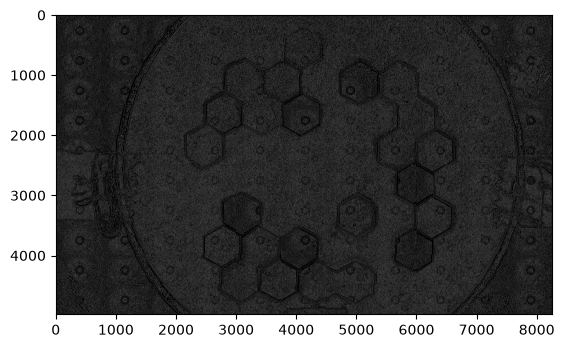

In [24]:
plt.imshow(edges_net_img, cmap='gray')
plt.show()

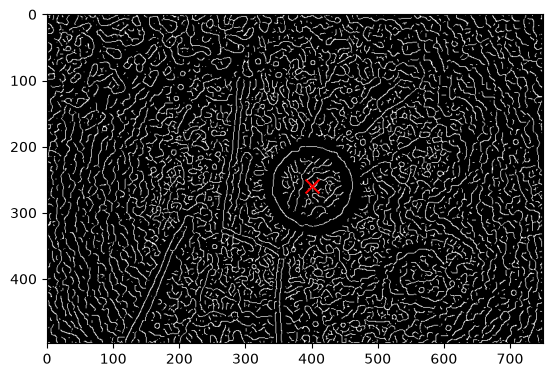

In [21]:
%matplotlib inline
plt.imshow(edges, cmap='gray')
plt.scatter(cx, cy, color='red', s=100, marker='x')
plt.show()

In [13]:
radii_found

array([47])

In [8]:
# shift (manual because the same offset per row and col applies)
shifted_cols = []
shift_x, shift_y = [-100,0,0,0,0,0,0,0,0,0,0], [0,0,0,0,0,0,0,0,0,0,0] 
for c in cols:

shifted = shift(img, shift=(dy, dx), mode='constant', cval=0, order=0)

NameError: name 'dy' is not defined

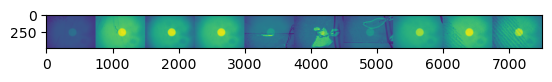

In [13]:
plt.imshow(rows[0])

In [12]:
rows[0].shape

(498, 7500)